In [1]:
import gzip
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Two Layer Neural Network

In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

    def sigmoid(self, s):
        return 1 / (1 + np.exp(-s))

    def softmax(self, s):
        # single sample batch-size =1
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        else:
            s = s - np.max(s, axis=1, keepdims=True)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    def predict(self, x):
        w1, w2 = self.params["w1"], self.params["w2"]
        b1, b2 = self.params["b1"], self.params["b2"]
        a1 = x @ w1 + b1
        z1 = self.sigmoid(a1)
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)
        return yhat

    def cross_entropy_error(self, y, yhat):
        if y.ndim == 1:
            y = y.reshape((1, y.size))
            yhat = yhat.reshape((1, yhat.size))
        batch_size = y.shape[0]
        # print(batch_size)
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    def loss(self, x, y):
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    # numerical gradient
    def numerical_gradient(self, x, y):
        h = 1e-4
        grad = {}
        # loop through every weight
        for k in self.params:
            grad[k] = np.zeros_like(self.params[k])
            # Iterate through every element
            # efficient multi-dimensional iterator object used to visit every element of one or more NumPy arrays without writing nested for loops
            iter = np.nditer(
                self.params[k], flags=["multi_index"], op_flags=["readwrite"]
            )
            while not iter.finished:
                idx = iter.multi_index
                tmp = self.params[k][idx]
                self.params[k][idx] = tmp + h
                # f(x+h)
                fh1 = self.loss(x, y)
                self.params[k][idx] = tmp - h
                # f(x-h)
                fh2 = self.loss(x, y)
                # Numerical gradient
                grad[k][idx] = (fh1 - fh2) / (2 * h)
                # Restore value
                self.params[k][idx] = tmp
                iter.iternext()
        return grad

    def save_weights(self, file_name="weights.pkl"):
        with open(file_name, "wb") as f:
            pickle.dump(self.params, f)

    def load_weights(self, file_name="weights.pkl"):
        with open(file_name, "rb") as f:
            self.params = pickle.load(f)


# IRIS

Initialize network and load data

In [ ]:
df = pd.read_csv("iris.csv", skipinitialspace=True)

# Input features
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

# One-hot encoded output
y = pd.get_dummies(df["species"], dtype=int)

# Convert to NumPy arrays
X = X.to_numpy()
y = y.to_numpy()

# Shuffle indices
np.random.seed(42)
indices = np.random.permutation(len(X))

# 80% training
train_size = int(0.8 * len(X))
train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Split data
X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# Check dimensions
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3)


X_train: (120, 4)
X_test:  (30, 4)
y_train: (120, 3)
y_test:  (30, 3)


Train IRIS neural network

 Iteration:  0  Loss:  1.0971317514823848
 Iteration:  1000  Loss:  1.0588714965373025
 Iteration:  2000  Loss:  0.5991680985009272
 Iteration:  3000  Loss:  0.40321266148889257
 Iteration:  4000  Loss:  0.36986346065594056
 Iteration:  5000  Loss:  0.29163732060165504
 Iteration:  6000  Loss:  0.2934343220872915
 Iteration:  7000  Loss:  0.23229408918773753
 Iteration:  8000  Loss:  0.1814355363217382
 Iteration:  9000  Loss:  0.20030387326217897


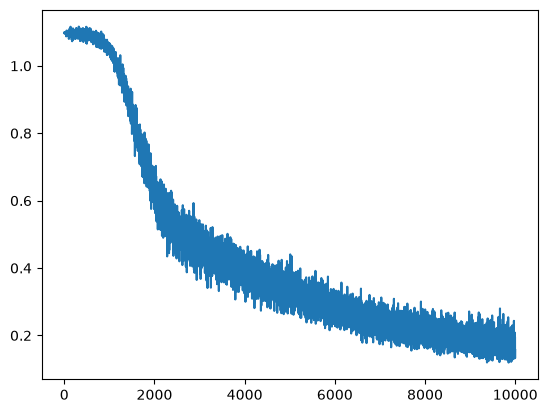

In [20]:
# hyper parameters
iters_num = 10000
train_size = X_train.shape[0]
batch_size = 64
learning_rate = 0.01
train_loss = []

# training loop
for i in range(iters_num):
    # mini-batch
    batch_mask = np.random.choice(train_size, batch_size)
    X_batch = X_train[batch_mask]
    y_batch = y_train[batch_mask]

    # forward propogation
    grad = iris_net.numerical_gradient(X_batch, y_batch)

    # backward propogation
    for key in iris_net.params:
        iris_net.params[key] -= learning_rate * grad[key]

    loss = iris_net.loss(X_batch, y_batch)
    train_loss.append(loss)
    if i % 1000 == 0:
        print(" Iteration: ", i, " Loss: ", loss)


iris_net.save_weights("bazzi_iris_nn_model.pkl")
plt.plot(train_loss)


Test IRIS neural network

In [ ]:
iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3)
iris_net.load_weights("bazzi_iris_nn_model.pkl")

# Evaluate the model on the complete Iris test dataset
iris_probabilities = iris_net.predict(X_test)
iris_predicted_labels = np.argmax(iris_probabilities, axis=1)
iris_true_labels = np.argmax(y_test, axis=1)
iris_accuracy = np.mean(iris_predicted_labels == iris_true_labels)
iris_class_names = np.array(["Setosa", "Versicolor", "Virginica"])
print(f"Iris test accuracy: {iris_accuracy:.2%}")

# Report the predicted and actual class for every test example
for index, (predicted_label, true_label) in enumerate(
    zip(iris_predicted_labels, iris_true_labels), start=1
):
    predicted_class = iris_class_names[predicted_label]
    true_class = iris_class_names[true_label]
    print(f"Example {index}: predicted={predicted_class}, actual={true_class}")


Iris test accuracy: 100.00%
Example 1: predicted=Versicolor, actual=Versicolor
Example 2: predicted=Setosa, actual=Setosa
Example 3: predicted=Versicolor, actual=Versicolor
Example 4: predicted=Versicolor, actual=Versicolor
Example 5: predicted=Setosa, actual=Setosa
Example 6: predicted=Versicolor, actual=Versicolor
Example 7: predicted=Virginica, actual=Virginica
Example 8: predicted=Virginica, actual=Virginica
Example 9: predicted=Setosa, actual=Setosa
Example 10: predicted=Versicolor, actual=Versicolor
Example 11: predicted=Virginica, actual=Virginica
Example 12: predicted=Virginica, actual=Virginica
Example 13: predicted=Setosa, actual=Setosa
Example 14: predicted=Virginica, actual=Virginica
Example 15: predicted=Setosa, actual=Setosa
Example 16: predicted=Versicolor, actual=Versicolor
Example 17: predicted=Virginica, actual=Virginica
Example 18: predicted=Virginica, actual=Virginica
Example 19: predicted=Versicolor, actual=Versicolor
Example 20: predicted=Virginica, actual=Virgini

# MNIST

Initialize network and load data

In [4]:
def load_mnist():
    with gzip.open("mnist/train-images-idx3-ubyte.gz", "rb") as f:
        X_train = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(
            -1, 28 * 28
        )
    with gzip.open("mnist/train-labels-idx1-ubyte.gz", "rb") as f:
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8).reshape(-1, 1)
        y_train = np.eye(10)[labels].reshape(-1, 10)
    with gzip.open("mnist/t10k-images-idx3-ubyte.gz", "rb") as f:
        X_test = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28 * 28)
    with gzip.open("mnist/t10k-labels-idx1-ubyte.gz", "rb") as f:
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8).reshape(-1, 1)
        y_test = np.eye(10)[labels].reshape(-1, 10)
    return X_train, y_train, X_test, y_test


mnist_net = TwoLayerNet(input_size=28 * 28, hidden_size=100, output_size=10)
X_train, y_train, X_test, y_test = load_mnist()


Train MNIST Neural Network

 Iteration:  0  Loss:  2.2958554786887433
 Iteration:  1  Loss:  2.2714147490193595
 Iteration:  2  Loss:  2.2402471192798394
 Iteration:  3  Loss:  2.258261079448882
 Iteration:  4  Loss:  2.2356021295707045
 Iteration:  5  Loss:  2.239007377648436
 Iteration:  6  Loss:  2.226990732275372
 Iteration:  7  Loss:  2.2035284594299602
 Iteration:  8  Loss:  2.2375230719984893
 Iteration:  9  Loss:  2.228257295558345


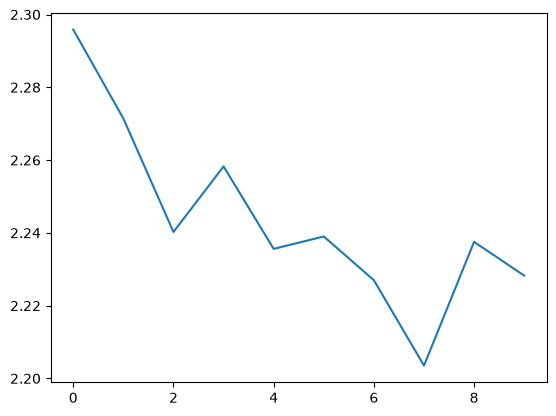

In [8]:
# hyper parameters
iters_num = 10
train_size = X_train.shape[0]
batch_size = 64
learning_rate = 0.01
train_loss = []

# training loop
for i in range(iters_num):
    # mini-batch
    batch_mask = np.random.choice(train_size, batch_size)
    X_batch = X_train[batch_mask]
    y_batch = y_train[batch_mask]

    # forward propogation
    grad = mnist_net.numerical_gradient(X_batch, y_batch)

    # backward propogation
    for key in mnist_net.params:
        mnist_net.params[key] -= learning_rate * grad[key]

    loss = mnist_net.loss(X_batch, y_batch)
    train_loss.append(loss)
    print(" Iteration: ", i, " Loss: ", loss)

mnist_net.save_weights("bazzi_mnist_nn_model.pkl")
plt.plot(train_loss)


Test MNIST Neural Network

Test accuracy: 28.46%


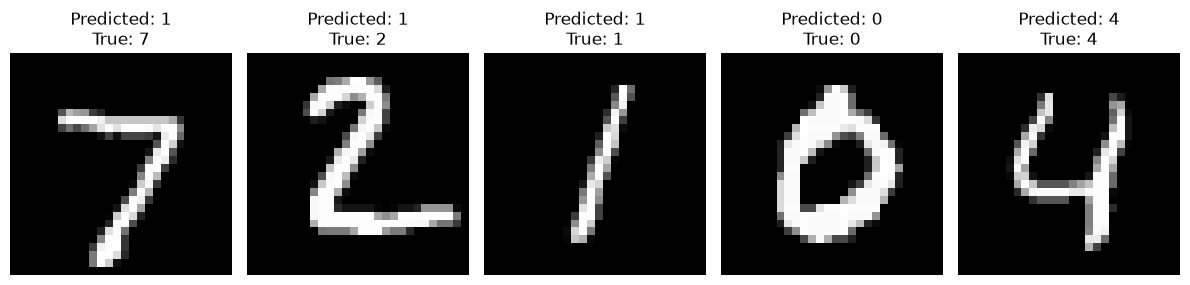

In [ ]:
mnist_net = TwoLayerNet(input_size=28 * 28, hidden_size=100, output_size=10)
mnist_net.load_weights("bazzi_mnist_nn_model.pkl")

# Evaluate the model on the complete MNIST test dataset
test_probabilities = mnist_net.predict(X_test)
predicted_labels = np.argmax(test_probabilities, axis=1)
true_labels = np.argmax(y_test, axis=1)
test_accuracy = np.mean(predicted_labels == true_labels)
print(f"Test accuracy: {test_accuracy:.2%}")

# Plot five test examples with predictions and ground truth
example_indices = np.arange(5)
figure, axes = plt.subplots(1, 5, figsize=(12, 3))

for axis, index in zip(axes, example_indices):
    axis.imshow(X_test[index].reshape(28, 28), cmap="gray")
    axis.set_title(f"Predicted: {predicted_labels[index]}\nTrue: {true_labels[index]}")
    axis.axis("off")

figure.tight_layout()
plt.show()
